# Movements parameters extraction

## Imports

In [15]:
import sys
import os

CUT_STRING = "src/master_thesis_data_analysis/data"

sys.path.append(os.path.join(os.getcwd().split(CUT_STRING)[0], CUT_STRING))
from new_framework import *

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.signal import find_peaks

## Literals

In [16]:
# ------------------------------------------------------------------ Input files
# CSV_FILE = Path("/home/ddacunto/Desktop/ros2_ws/recording_csv/NOEMI_BIANCAMANO/CHECK_XY/recording_1.csv")
CSV_FILE = Path("/home/ddacunto/Desktop/ros2_ws/recording_csv/NOEMI_BIANCAMANO/BURSTc_XY/recording_11.csv")
YAML_PATHS_FILE = Path("/home/ddacunto/Desktop/ros2_ws/src/unisa_acg_ros2/haptics/haptic_interaction_teach_and_record_demo/config/paths.yaml")

TASK = CSV_FILE.parent.name

POSITION_COLUMNS = ["position_x", "position_y", "position_z"]
VELOCITY_COLUMNS = ["twist_linear_x", "twist_linear_y", "twist_linear_z"]

# ------------------------------------------------- Low-pass Chebyshev II filter
FILTER_ORDER = 11
FILTER_CUTOFF_HZ = 16
FILTER_STOPBAND_DB = 80
TARGET_FREQUENCY = 500  # Hz
# ------------------------------------------------------ Low-speed edge trimming
SPEED_THRESHOLD = 0.035  # m/s (or relative, e.g. 0.05 * speed.max())
EDGE_MARGIN_S = 0.03     # safety margin kept around the above-threshold part

# ------------------------------------------ Waypoints: normalized -> device frame
SWAP_YZ_WAYPOINTS = False
WS_MIN = np.array([-0.082, -0.065, -0.085])
WS_MAX = np.array([0.082, 0.065, 0.085])

# ---------------------------------------------------------------- Lognormal fit
FIT_OPTIONS = dict(
    sigma_bounds=(0.05, 1.5),  # allowed range for the lognormal sigma
    max_lead=1.0,              # t0 may precede the window start by max_lead * window duration
)
STEPS_TO_PLOT = None  # None = plot every step, or e.g. [0, 1]

# --------------------------------------------------------------- Joint refinement
REFINE_OPTIONS = dict(
    t0_shift_frac=0.5,  # t0 may move by +/- this fraction of the stroke window duration
    mu_shift=1.0,       # mu may move by +/- this amount
    reg_weight=0.0,     # > 0 pulls the parameters toward the sequential solution
)

# ------------------------------------------------------------------------ Lengths
LOCK_D_TO_GEOMETRY = True  # D of each stroke = measured path length between its two speed minima

# ------------------------------------------------------- Geometric reconstruction
ANGLE_STEP_RAD = np.deg2rad(1.0)  # angular sensitivity of the exit/entry angles
ANGLE_LIMITS = (-np.pi, np.pi)
PLOT_RECONSTRUCTIONS = True

# ------------------------------------------ Model speed trimmed by travelled distance
MODEL_END_TIME_S = 10.0  # end of the time grid on which the model speed is evaluated
TRIM_START_M = 0.00005     # .05 mm
TRIM_END_M = 0.00005       # .05 mm

## Tasks

In [17]:
def load_waypoints(yaml_file, task):
    with open(yaml_file, "r") as f:
        paths = yaml.safe_load(f)["paths"]
    for path in paths:
        if path["name"] == task:
            return path["waypoints"]
    raise KeyError(f"Task '{task}' not found in {yaml_file}")


def waypoints_to_array(waypoints, swap_yz=False, ws_min=None, ws_max=None):
    """Convert the list of {'x','y','z'} dicts (normalized) into an Nx3 array in device coordinates."""
    arr = np.array([[w["x"], w["y"], w["z"]] for w in waypoints], dtype=float)
    if swap_yz:
        arr[:, [1, 2]] = arr[:, [2, 1]]
    if ws_min is not None and ws_max is not None:
        ws_min = np.asarray(ws_min, dtype=float)
        ws_max = np.asarray(ws_max, dtype=float)
        arr = ws_min + arr * (ws_max - ws_min)
    return arr


WAYPOINTS = load_waypoints(YAML_PATHS_FILE, TASK)
waypoints_xyz = waypoints_to_array(WAYPOINTS, SWAP_YZ_WAYPOINTS, WS_MIN, WS_MAX)
csv_data = pd.read_csv(CSV_FILE)
csv_data['timestamp'] = csv_data['timestamp'] - csv_data['timestamp'].iloc[0]  # normalize timestamps to start at 0
csv_data['timestamp'] = csv_data['timestamp'] / 1e9  # convert from nanoseconds to seconds
print(WAYPOINTS)

[{'x': 0.1, 'y': 0.2, 'z': 0.5}, {'x': 0.9, 'y': 0.5, 'z': 0.5}, {'x': 0.1, 'y': 0.8, 'z': 0.5}]


## Pipeline

### Load the recording data

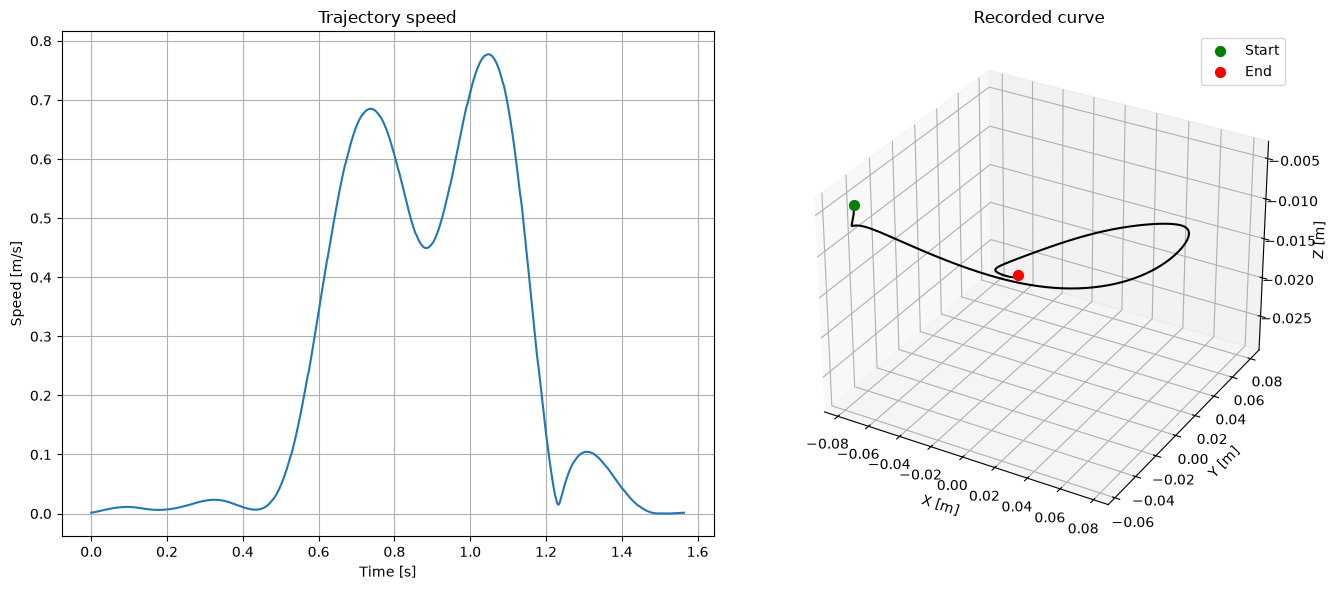

In [18]:
recording = Recording(
  trajectory=Trajectory(
    vx  = csv_data['twist_linear_x'].to_numpy(),
    vy  = csv_data['twist_linear_y'].to_numpy(),
    vz  = csv_data['twist_linear_z'].to_numpy(),
  ),
  curve=Curve(
    x   = csv_data['position_x'].to_numpy(),
    y   = csv_data['position_y'].to_numpy(),
    z   = csv_data['position_z'].to_numpy(),
  ),
    t   = csv_data['timestamp'].to_numpy()
)
filter = Chebyshev(order=FILTER_ORDER, cutoff=FILTER_CUTOFF_HZ, stopband_attenuation=FILTER_STOPBAND_DB)
resampler = Resample(target_fs=TARGET_FREQUENCY)
recording.trajectory = filter.apply(recording.trajectory) # type: ignore
recording.curve = filter.apply(recording.curve) # type: ignore
recording.trajectory = resampler.apply(recording.trajectory) # type: ignore
recording.curve = resampler.apply(recording.curve) # type: ignore

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(
  recording.trajectory.t,
  recording.trajectory.speed,
  color="tab:blue",
  linewidth=1.5,
)
ax1.set_xlabel("Time [s]")
ax1.set_ylabel("Speed [m/s]")
ax1.set_title("Trajectory speed")
ax1.grid(True)

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
curve_points = np.asarray(recording.curve.points)
ax2.plot(
  curve_points[:, 0],
  curve_points[:, 1],
  curve_points[:, 2],
  color="black",
  linewidth=1.5,
)
ax2.scatter(*curve_points[0], color="green", s=50, label="Start")
ax2.scatter(*curve_points[-1], color="red", s=50, label="End")
ax2.set_xlabel("X [m]")
ax2.set_ylabel("Y [m]")
ax2.set_zlabel("Z [m]")
ax2.set_title("Recorded curve")
ax2.legend()

plt.tight_layout()
plt.show()

### Detect Speed Minima and Maxima

In [19]:
def find_minima_maxima(speed:np.ndarray, samples_distance:float|None=None, prominence:float|None=None) -> tuple[list[int], list[int]]:
    """Find the indices of the speed minima and maxima in the given speed array."""
    # Find local maxima
    maxima_indices, _ = find_peaks(speed, distance=samples_distance, prominence=prominence)
    # Find local minima by inverting the speed
    minima_indices, _ = find_peaks(-speed, distance=samples_distance, prominence=prominence)
    try:
        if minima_indices[0] > maxima_indices[0]:
            if speed[0] < speed[maxima_indices[0]]:
                minima_indices = np.r_[0, minima_indices]
            else:
                if speed[0] > speed[minima_indices[0]]:
                    maxima_indices = np.r_[0, maxima_indices]
            
        if minima_indices[-1] < maxima_indices[-1]:
            if speed[-1] < speed[maxima_indices[-1]]:
                minima_indices = np.r_[minima_indices, speed.size - 1]
            else:
                if speed[-1] > speed[minima_indices[-1]]:
                    maxima_indices = np.r_[maxima_indices, speed.size - 1]
    except IndexError:
        if len(minima_indices) == 0 and len(maxima_indices) == 1:
            minima_indices = np.array([0, speed.size - 1])
    return minima_indices, maxima_indices

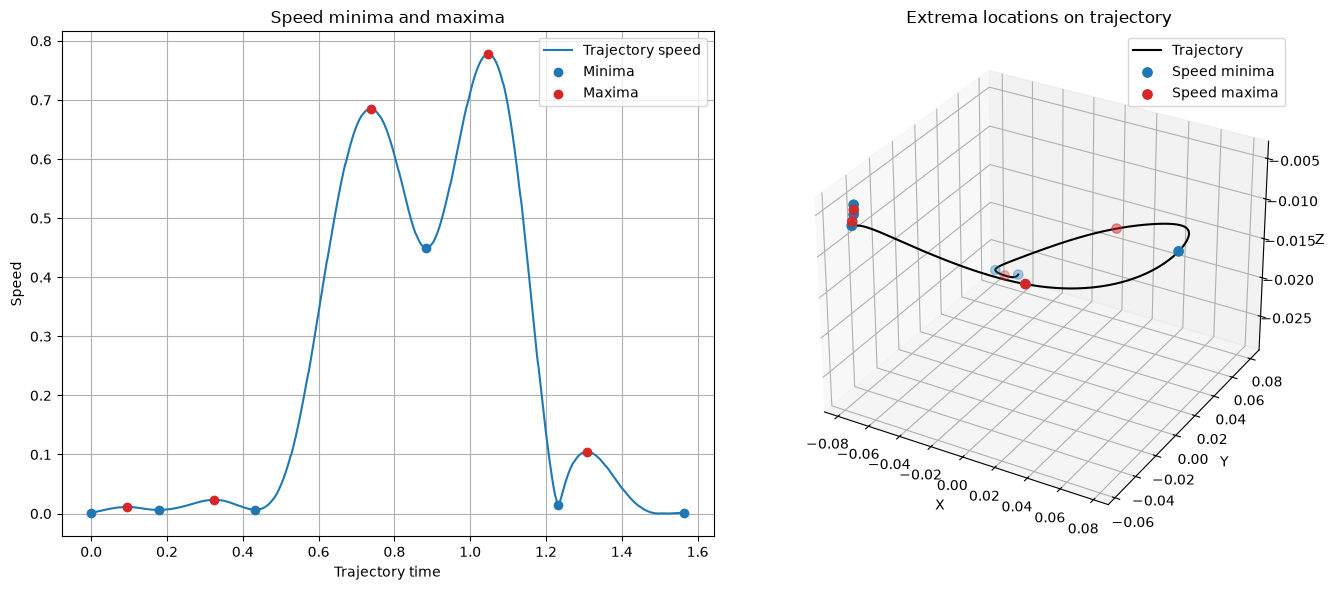

Detected 6 speed minima and 5 speed maxima.
Speed minima indices: [  0  89 216 442 616 782]
Speed maxima indices: [ 47 162 369 524 654]
Speed profile length: 783


In [20]:
speed = recording.trajectory.speed
speed_time = recording.trajectory.t

# Detect significant local extrema.
peak_distance = max(1, speed.size // 100)
prominence = 0.008
TIME_DISTANCE = .1 #s
PROMINENCE = .005 #m/s
frequency = np.median(np.diff(recording.trajectory.t))  # Estimate the sampling frequency from the trajectory timestamps
minima_idx, maxima_idx = find_minima_maxima(speed, samples_distance=TIME_DISTANCE / frequency, prominence = PROMINENCE)


# Interpolate trajectory positions onto the speed samples.
speed_positions = np.column_stack([
  np.interp(speed_time, recording.trajectory.t, recording.curve.points[:, axis])
  for axis in range(3)
])

fig = plt.figure(figsize=(14, 6))

# Speed profile with extrema.
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(speed_time, speed, label="Trajectory speed")
ax1.scatter(speed_time[minima_idx], speed[minima_idx],
      color="tab:blue", label="Minima", zorder=3)
ax1.scatter(speed_time[maxima_idx], speed[maxima_idx],
      color="tab:red", label="Maxima", zorder=3)
ax1.set_xlabel("Trajectory time")
ax1.set_ylabel("Speed")
ax1.set_title("Speed minima and maxima")
ax1.grid(True)
ax1.legend()

# 3D trajectory with extrema.
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot(
  speed_positions[:, 0],
  speed_positions[:, 1],
  speed_positions[:, 2],
  color="black",
  label="Trajectory",
)
ax2.scatter(
  speed_positions[minima_idx, 0],
  speed_positions[minima_idx, 1],
  speed_positions[minima_idx, 2],
  color="tab:blue",
  s=45,
  label="Speed minima",
)
ax2.scatter(
  speed_positions[maxima_idx, 0],
  speed_positions[maxima_idx, 1],
  speed_positions[maxima_idx, 2],
  color="tab:red",
  s=45,
  label="Speed maxima",
)

ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z")
ax2.set_title("Extrema locations on trajectory")
ax2.legend()

plt.tight_layout()
plt.show()
print(f"Detected {len(minima_idx)} speed minima and {len(maxima_idx)} speed maxima.")
print(f"Speed minima indices: {minima_idx}")
print(f"Speed maxima indices: {maxima_idx}")
print(f"Speed profile length: {len(speed)}")

### Extract trajectory parameters

In [29]:
ls = LeastSquares(
  boundaries=minima_idx,
  lock_D=LOCK_D_TO_GEOMETRY,
  refine=True
)

reconstructed_strokes = ls.approximate(recording)

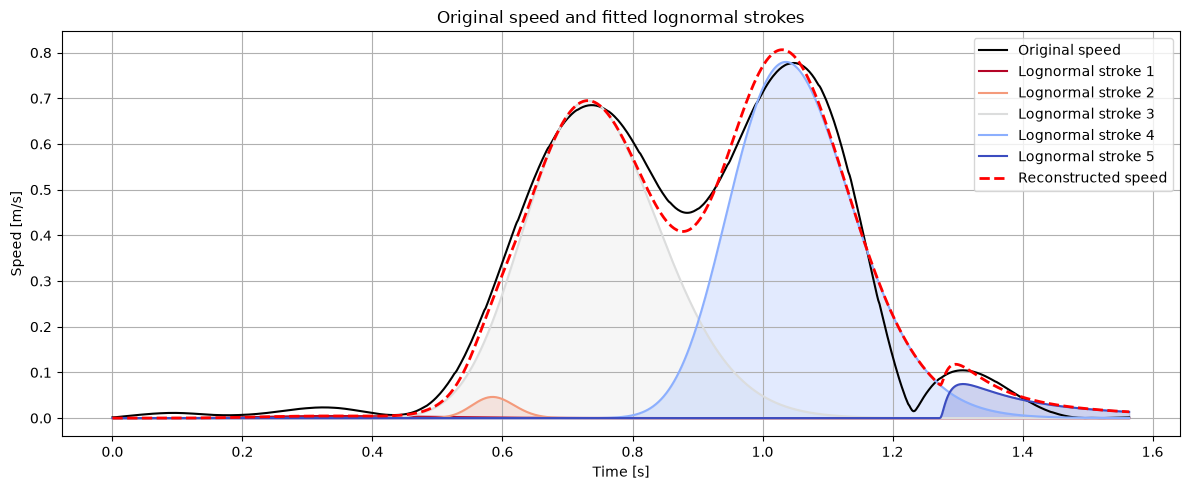

SNR: 21.32 dB


In [30]:
# Inspect this once if the attribute name is unknown:
# print(vars(reconstructed_strokes))

stroke_list = reconstructed_strokes.strokes  # change to the actual collection attribute if needed
reconstructed_stroke_list = reconstructed_strokes.strokes

t = recording.t
reconstructed_speed = np.zeros_like(t, dtype=float)
colors = plt.cm.coolwarm_r(np.linspace(0, 1, len(stroke_list)))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
  t,
  recording.trajectory.speed,
  color="black",
  linewidth=1.5,
  label="Original speed",
)

for i, (stroke, color) in enumerate(zip(stroke_list, colors), start=1):
  t0 = float(stroke.to)
  mu = float(stroke.mu)
  sigma = float(stroke.sigma)
  D = abs(float(stroke.D))

  tau = t - t0
  valid = tau > 0
  density = np.zeros_like(t, dtype=float)

  density[valid] = (
    D
    / (sigma * np.sqrt(2 * np.pi) * tau[valid])
    * np.exp(-((np.log(tau[valid]) - mu) ** 2) / (2 * sigma**2))
  )

  reconstructed_speed += density

  ax.plot(t, density, color=color, linewidth=1.5,
      label=f"Lognormal stroke {i}")
  ax.fill_between(t, density, color=color, alpha=0.25)

ax.plot(
  t,
  reconstructed_speed,
  "--",
  color="red",
  linewidth=2,
  label="Reconstructed speed",
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Speed [m/s]")
ax.set_title("Original speed and fitted lognormal strokes")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

print(f"SNR: {SNR(recording.trajectory.speed, reconstructed_speed):.2f} dB")


In [23]:
def filter_strokes_by_D(strokes:StrokeSequence, threshold:float) -> tuple[StrokeSequence, Stroke|None]:
    Ds = []
    for stroke in strokes:
        Ds.append(stroke.D)

    filtered_strokes = []
    for stroke in strokes:
        if stroke.D > threshold:
            filtered_strokes.append(stroke)

    corrective_last_stroke = None
    last_filtered_index = strokes.strokes.index(filtered_strokes[-1])
    if len(strokes) > last_filtered_index + 1:
        corrective_last_stroke = strokes.get(last_filtered_index + 1)

    return StrokeSequence(filtered_strokes), corrective_last_stroke

filtered_strokes, last_stroke = filter_strokes_by_D(reconstructed_strokes, 0.075)
#start_time = filtered_strokes.strokes[0].to
#for stroke in filtered_strokes.strokes:
#    stroke.to -= start_time
print([f"stroke to {stroke.to}" for stroke in filtered_strokes])



['stroke to -0.020000000000000014', 'stroke to 0.5360000000000001']


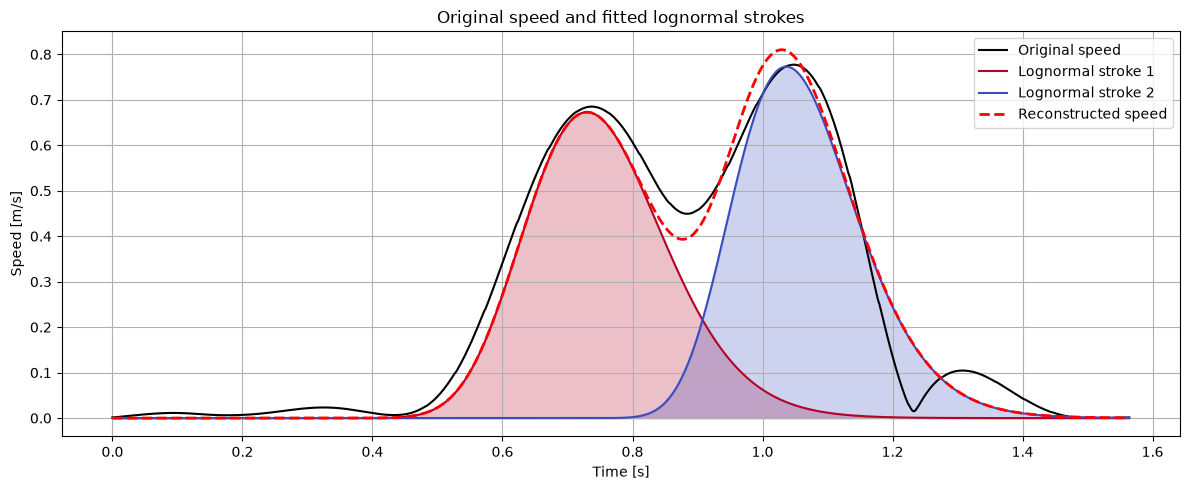

SNR: 18.76 dB
Filtered stroke parameters:
Stroke 1: to=-0.020000, mu=-0.267945, sigma=0.141135, D=0.180291
Stroke 2: to=0.536000, mu=-0.657289, sigma=0.186334, D=0.183877


In [24]:
# Inspect this once if the attribute name is unknown:
# print(vars(strokes))

stroke_list = filtered_strokes.strokes  # change to the actual collection attribute if needed

t = recording.t
reconstructed_speed = np.zeros_like(t, dtype=float)
colors = plt.cm.coolwarm_r(np.linspace(0, 1, len(stroke_list)))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
  t,
  recording.trajectory.speed,
  color="black",
  linewidth=1.5,
  label="Original speed",
)

for i, (stroke, color) in enumerate(zip(stroke_list, colors), start=1):
  t0 = float(stroke.to)
  mu = float(stroke.mu)
  sigma = float(stroke.sigma)
  D = abs(float(stroke.D))

  tau = t - t0
  valid = tau > 0
  density = np.zeros_like(t, dtype=float)

  density[valid] = (
    D
    / (sigma * np.sqrt(2 * np.pi) * tau[valid])
    * np.exp(-((np.log(tau[valid]) - mu) ** 2) / (2 * sigma**2))
  )

  reconstructed_speed += density

  ax.plot(t, density, color=color, linewidth=1.5,
      label=f"Lognormal stroke {i}")
  ax.fill_between(t, density, color=color, alpha=0.25)

ax.plot(
  t,
  reconstructed_speed,
  "--",
  color="red",
  linewidth=2,
  label="Reconstructed speed",
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Speed [m/s]")
ax.set_title("Original speed and fitted lognormal strokes")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

print(f"SNR: {SNR(recording.trajectory.speed, reconstructed_speed):.2f} dB")
print("Filtered stroke parameters:")
for i, stroke in enumerate(stroke_list, start=1):
  print(
    f"Stroke {i}: "
    f"to={float(stroke.to):.6f}, "
    f"mu={float(stroke.mu):.6f}, "
    f"sigma={float(stroke.sigma):.6f}, "
    f"D={float(stroke.D):.6f}"
  )

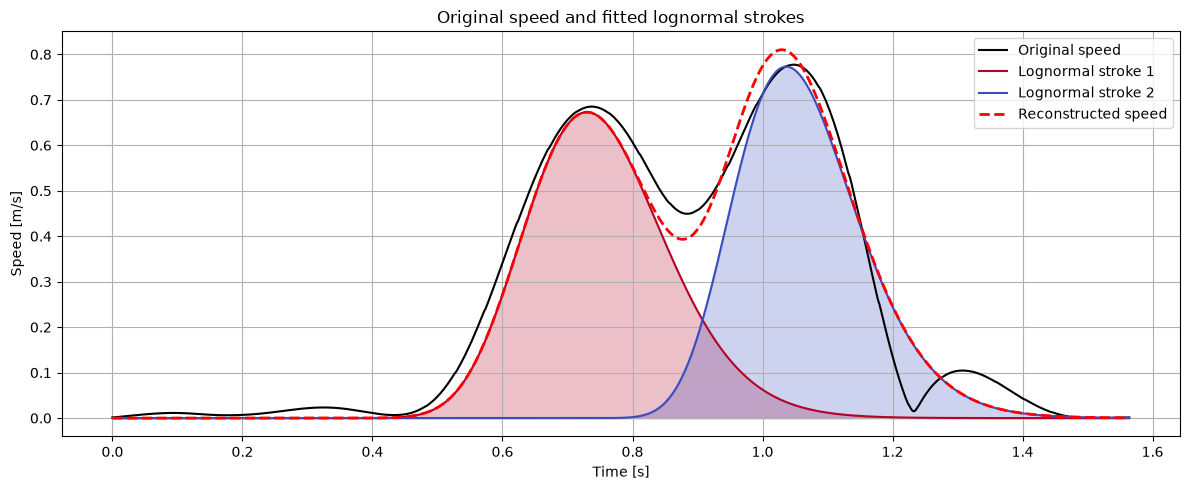

SNR: 18.76 dB
Filtered stroke parameters:
Stroke 1: to=-0.020000, mu=-0.267945, sigma=0.141135, D=0.180291
Stroke 2: to=0.536000, mu=-0.657289, sigma=0.186334, D=0.183877


In [25]:
# Inspect this once if the attribute name is unknown:
# print(vars(strokes))

stroke_list = filtered_strokes.strokes  # change to the actual collection attribute if needed

t = recording.t
reconstructed_speed = np.zeros_like(t, dtype=float)
colors = plt.cm.coolwarm_r(np.linspace(0, 1, len(stroke_list)))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
  t,
  recording.trajectory.speed,
  color="black",
  linewidth=1.5,
  label="Original speed",
)

for i, (stroke, color) in enumerate(zip(stroke_list, colors), start=1):
  t0 = float(stroke.to)
  mu = float(stroke.mu)
  sigma = float(stroke.sigma)
  D = abs(float(stroke.D))

  tau = t - t0
  valid = tau > 0
  density = np.zeros_like(t, dtype=float)

  density[valid] = (
    D
    / (sigma * np.sqrt(2 * np.pi) * tau[valid])
    * np.exp(-((np.log(tau[valid]) - mu) ** 2) / (2 * sigma**2))
  )

  reconstructed_speed += density

  ax.plot(t, density, color=color, linewidth=1.5,
      label=f"Lognormal stroke {i}")
  ax.fill_between(t, density, color=color, alpha=0.25)

ax.plot(
  t,
  reconstructed_speed,
  "--",
  color="red",
  linewidth=2,
  label="Reconstructed speed",
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Speed [m/s]")
ax.set_title("Original speed and fitted lognormal strokes")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

print(f"SNR: {SNR(recording.trajectory.speed, reconstructed_speed):.2f} dB")
print("Filtered stroke parameters:")
for i, stroke in enumerate(stroke_list, start=1):
  print(
    f"Stroke {i}: "
    f"to={float(stroke.to):.6f}, "
    f"mu={float(stroke.mu):.6f}, "
    f"sigma={float(stroke.sigma):.6f}, "
    f"D={float(stroke.D):.6f}"
  )

### Extract curve parameters

A Bézier spline is a sequence of curves. Being $P_0',P_1',P_2',P_3'$ the points of the next curve $B'(\nu)$, $C^0$ continuity imposes
$$P_0'=P_3$$


A cubic Bézier curve is defined by 4 points $P_0,P_1,P_2,P_3$:
$$B(\nu)=(1-\nu)^3P_0+3(1-\nu)^2\nu\,P_1+3(1-\nu)\nu^2P_2+\nu^3P_3,\qquad \nu\in[0,1]$$
Its derivative with respect to $\nu$ is:
$$\frac{dB}{d\nu}=3(1-\nu)^2(P_1-P_0)+6(1-\nu)\nu(P_2-P_1)+3\nu^2(P_3-P_2)$$

$C^0$ continuity ensures that the curve is linked at the joint: $$B(1)=P_3=B'(0)=P_0'$$
$C^1$ continuity imposes that the derivative at the joint is the same: $$\frac{dB'}{d\nu}(0)=3(P_1'-P_0')=\frac{dB}{d\nu}(1)=3(P_3-P_2)\Rightarrow P_1'=2P_3-P_2$$
In other words, $P_3$ is the mid point of the segment $P_2P_1'$.

So, the two points $P_1$ and $P_2$ are computed as: $$P_1 = P_0 + \lambda_s\cdot c \cdot u_s,\qquad P_2 = P_3 - \lambda_e\cdot c \cdot u_e$$

Let $c=\|P_3-P_0\|$ be the chord of the curve. For the curve $k$ the network generates:
- the reached point as a difference $\Delta P$ with respect to $P_0$: $P_3=P_0+\Delta P$, so $c=\|\Delta P\|$
- the direction of entry in $P_3$: $\mathbf{u_e}$
- a parameter proportional to the second handle length: $\lambda_e$

The point $P_0$ and the exit direction $\mathbf{u_s}$ and parameter $\lambda_s$ are inherited from the previous curve, so that $C^0$ and $C^1$ hold; only for the first curve are $\mathbf{u_s}$ and $\lambda_s$ generated too.
$$P_1=P_0+\lambda_s\,c\,\mathbf{u_s},\qquad P_2=P_3-\lambda_e\,c\,\mathbf{u_e}$$
With the same parameter interval for consecutive curves, $P_1'=2P_3-P_2$ gives, for the next curve (chord $c'$),
$$\mathbf{u_s'}=\mathbf{u_e},\qquad \lambda_s'=\lambda_e\,\frac{c}{c'}$$
The length $D=\int_0^1\left\|\frac{dB}{d\nu}\right\|d\nu$ is not generated: it is computed from the curve.

In [26]:
minima_idx_strokes = []

USE_FILTERED = True

if USE_FILTERED:
  for stroke in filtered_strokes:
    stroke_index = reconstructed_strokes.strokes.index(stroke)
    minima_idx_strokes.append(minima_idx[stroke_index])
    minima_idx_strokes.append(minima_idx[stroke_index + 1])  # Include the next minimum for the last stroke

  minima_idx_strokes = sorted(set(minima_idx_strokes))  # Remove duplicates and sort


  start_time = recording.t[minima_idx_strokes[0]]
  end_time = recording.t[minima_idx_strokes[-1]]
  Ds = [stroke.D for stroke in filtered_strokes]

else:
  start_time = recording.t[minima_idx[0]]
  end_time = recording.t[minima_idx[-1]]
  minima_idx_strokes = minima_idx  # Use all minima indices if not filtering
  Ds = [stroke.D for stroke in reconstructed_strokes]

print(f"Start time: {start_time}, End time: {end_time}")

approx = CubicBezierC1Approximation(boundaries=minima_idx_strokes, D=Ds, trajectory=recording.trajectory) # type: ignore
curve_params, bezier = approx.approximate(recording.curve)


Start time: 0.432, End time: 1.232


In [27]:
for key, value in curve_params.items():
    print(f"{key}: {value}")


degree: 3
continuity: C1
time_scale: time
boundaries: [216 442 616]
D: [0.18029059 0.18387738]
start_point: [-0.07413742 -0.05556574 -0.00655341]
by_stroke: [{'stroke': 0, 'delta_p': array([ 0.15165693,  0.07291578, -0.00266143]), 'u_e': array([0.04408741, 0.9987543 , 0.02336967]), 'lambda_e': 0.40225415329414477, 'u_s': array([ 0.87500489, -0.48191913, -0.04604766]), 'lambda_s': 0.0059338718485692455, 'duration': 0.452}, {'stroke': 1, 'delta_p': array([-0.15502296,  0.05998302, -0.01791139]), 'u_e': array([-0.15898111,  0.50905717, -0.84592305]), 'lambda_e': 0.010394830964455974, 'u_s': array([0.04408741, 0.9987543 , 0.02336967]), 'lambda_s': 0.40225415329414477, 'duration': 0.348}]
strokes: [{'stroke': 0, 'boundary_start': np.int64(216), 'boundary_end': np.int64(442), 'D_target_m': 0.18029058770468376, 'D_bezier_m': 0.18142914396720486, 'D_error_m': 0.001138556262521101, 'duration': 0.452, 'speed_start_m_s': 0.006628195974986966, 'speed_end_m_s': 0.44932203253242203, 'rmse_m': 0.0192

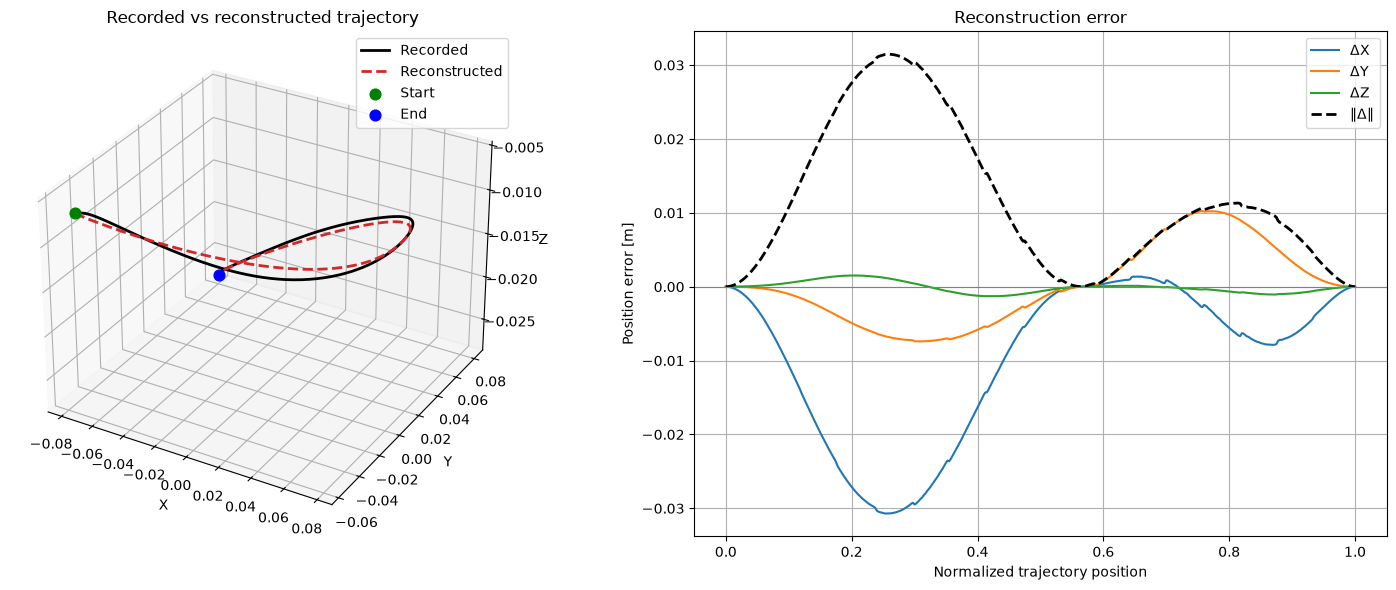

SNR: 14.47 dB
Mean error: 0.011655 m
Maximum error: 0.031459 m


In [28]:
reconstructed = approx.generate_curve()
filtered_curve = Curve(
    x=recording.curve.x[minima_idx_strokes[0]:minima_idx_strokes[-1]+1],
    y=recording.curve.y[minima_idx_strokes[0]:minima_idx_strokes[-1]+1],
    z=recording.curve.z[minima_idx_strokes[0]:minima_idx_strokes[-1]+1],
    t=recording.curve.t[minima_idx_strokes[0]:minima_idx_strokes[-1]+1]
)
original_points = np.asarray(filtered_curve.points)
reconstructed_points = np.asarray(reconstructed.points)

# Compare both curves using normalized sample positions.
u_original = np.linspace(0.0, 1.0, len(original_points))
u_reconstructed = np.linspace(0.0, 1.0, len(reconstructed_points))

reconstructed_aligned = np.column_stack([
  np.interp(u_original, u_reconstructed, reconstructed_points[:, axis])
  for axis in range(3)
])

difference = original_points - reconstructed_aligned
error_norm = np.linalg.norm(difference, axis=1)

fig = plt.figure(figsize=(15, 6))

# 3D trajectory comparison
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot(*original_points.T, color="black", linewidth=2, label="Recorded")
ax1.plot(*reconstructed_aligned.T, color="tab:red", linestyle="--",
     linewidth=2, label="Reconstructed")

ax1.scatter(*original_points[0], color="green", s=60, label="Start")
ax1.scatter(*original_points[-1], color="blue", s=60, label="End")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")
ax1.set_title("Recorded vs reconstructed trajectory")
ax1.legend()

# Difference plot
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(u_original, difference[:, 0], label="ΔX")
ax2.plot(u_original, difference[:, 1], label="ΔY")
ax2.plot(u_original, difference[:, 2], label="ΔZ")
ax2.plot(u_original, error_norm, "k--", linewidth=2, label="‖Δ‖")

ax2.axhline(0, color="gray", linewidth=0.8)
ax2.set_xlabel("Normalized trajectory position")
ax2.set_ylabel("Position error [m]")
ax2.set_title("Reconstruction error")
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

print(f"SNR: {filtered_curve.snr(reconstructed):.2f} dB")
print(f"Mean error: {error_norm.mean():.6f} m")
print(f"Maximum error: {error_norm.max():.6f} m")